# Лабораторна робота №5
## Вступ до TensorFlow і побудова простої нейронної мережі для регресії

**Студент:** Вадим Калашник  
**Варіант:** 10  
**Дослідження Варіанта 10:** Використання `EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)` із граничною кількістю епох `epochs=300`.  
**Фіксований Seed:** `SEED = 42`  

**Мета роботи:** Навчитися створювати тензори, перевіряти їхні `shape` і `dtype`, будувати та навчати модель `tf.keras.Sequential` для розв'язання задачі нелінійної регресії, оцінювати її на незалежних даних, аналізувати історію навчання за допомогою EarlyStopping та зберігати модель у форматі `.keras`.

In [1]:
%pip install tensorflow


  Using cached tensorflow-2.22.0rc0-cp314-cp314-win_amd64.whl.metadata (4.6 kB)
Using cached tensorflow-2.22.0rc0-cp314-cp314-win_amd64.whl (384.1 MB)
Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt

print("Версія TensorFlow:", tf.__version__)

# 1. Створення констант і змінних
a = tf.constant([[1., 2.], [3., 4.]], dtype=tf.float32)
b = tf.constant([10., 20.], dtype=tf.float32)

w = tf.Variable([0.2, 0.5], dtype=tf.float32)
w.assign([0.3, 0.6])

# 2. Виведення характеристик
print("\n--- Характеристики тензора a ---")
print("Форма (shape):", a.shape)
print("Тип даних (dtype):", a.dtype)
print("Ранг (rank):", tf.rank(a).numpy())

print("\n--- Результати операцій ---")
print("1. Додавання a + b (Broadcasting):\n", (a + b).numpy())
print("2. Поелементне множення a * a:\n", (a * a).numpy())
print("3. Матричне множення tf.matmul(a, a):\n", tf.matmul(a, a).numpy())
print("4. Оновлені ваги w:\n", w.numpy())

Версія TensorFlow: 2.22.0-rc0

--- Характеристики тензора a ---
Форма (shape): (2, 2)
Тип даних (dtype): <dtype: 'float32'>
Ранг (rank): 2

--- Результати операцій ---
1. Додавання a + b (Broadcasting):
 [[11. 22.]
 [13. 24.]]
2. Поелементне множення a * a:
 [[ 1.  4.]
 [ 9. 16.]]
3. Матричне множення tf.matmul(a, a):
 [[ 7. 10.]
 [15. 22.]]
4. Оновлені ваги w:
 [0.3 0.6]


**Пояснення тензорних операцій:**
1. **Чому `a + b` можливе (Broadcasting):** Тензор `a` має форму `(2, 2)`, а тензор `b` — `(2,)`. Завдяки механізму *broadcasting* TensorFlow автоматично розширює вектори `b` вздовж відсутнього виміру до форми `(2, 2)` (повторюючи рядок `[10., 20.]`), після чого виконує додавання відповідних елементів.
2. **Відмінність `a * a` від `tf.matmul(a, a)`:**
   * `a * a` виконує **поелементне множення** (Hadamard product): кожен елемент матриці підноситься до квадрата ($1^2=1, 2^2=4, 3^2=9, 4^2=16$).
   * `tf.matmul(a, a)` виконує класичне **матричне множення** (рядок на стовпчик), за правилами лінійної алгебри.

Розмірність x_train: (420, 1), y_train: (420, 1)
Розмірність x_val:   (90, 1), y_val:   (90, 1)
Розмірність x_test:  (90, 1), y_test:  (90, 1)


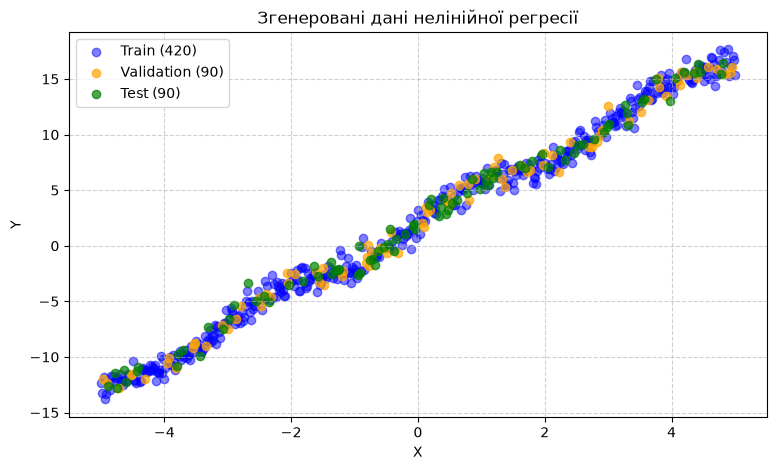

In [3]:
SEED = 42
keras.utils.set_random_seed(SEED)
rng = np.random.default_rng(SEED)

# Генерація даних нелінійної регресії
x = np.linspace(-5, 5, 600, dtype=np.float32)
noise = rng.normal(0, 0.7, x.shape).astype(np.float32)
y = 3 * x + 2 + 0.8 * np.sin(2 * x) + noise

# Зміна форми на (600, 1) та випадкове перемішування
x, y = x.reshape(-1, 1), y.reshape(-1, 1)
idx = rng.permutation(len(x))
x, y = x[idx], y[idx]

# Поділ у співвідношенні 70 / 15 / 15
x_train, y_train = x[:420], y[:420]
x_val, y_val = x[420:510], y[420:510]
x_test, y_test = x[510:], y[510:]

print(f"Розмірність x_train: {x_train.shape}, y_train: {y_train.shape}")
print(f"Розмірність x_val:   {x_val.shape}, y_val:   {y_val.shape}")
print(f"Розмірність x_test:  {x_test.shape}, y_test:  {y_test.shape}")

# Візуалізація розподілу даних
plt.figure(figsize=(9, 5))
plt.scatter(x_train, y_train, alpha=0.5, color="blue", label="Train (420)")
plt.scatter(x_val, y_val, alpha=0.7, color="orange", label="Validation (90)")
plt.scatter(x_test, y_test, alpha=0.7, color="green", label="Test (90)")
plt.title("Згенеровані дані нелінійної регресії")
plt.xlabel("X")
plt.ylabel("Y")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.savefig("fig1_dataset_split.png", dpi=300)
plt.show()

**Висновок до Кроку 2:**
Згенеровано 600 точок нелінійної функції $y = 3x + 2 + 0.8\sin(2x) + \epsilon$. Дані розбито на три незалежні вибірки: Навчальну (70%), Валідаційну (15%) та Тестову (15%). Форма одного входу дорівнює `(1,)`.

In [4]:
# Функція побудови архітектури Keras Sequential
def build_model():
    return keras.Sequential([
        layers.Input(shape=(1,)),
        layers.Dense(16, activation="relu"),
        layers.Dense(16, activation="relu"),
        layers.Dense(1)  # Вихідний шар без активації для регресії
    ])

# 1. Побудова та компіляція базової моделі
keras.utils.set_random_seed(SEED)
base_model = build_model()

base_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.01),
    loss="mse",
    metrics=["mae"]
)

print("--- Архітектура Нейронної Мережі ---")
base_model.summary()

# Навчання базової моделі (100 епох)
history_base = base_model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=100,
    batch_size=32,
    verbose=0
)

min_val_loss_base = min(history_base.history["val_loss"])
print(f"\nБазова модель — найменший val_loss: {min_val_loss_base:.4f}")

--- Архітектура Нейронної Мережі ---


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 321 (1.25 KB)

 Trainable params: 321 (1.25 KB)

 Non-trainable params: 0 (0.00 B)


Базова модель — найменший val_loss: 0.6122


In [5]:
# 2. Побудова та компіляція моделі для Варіанта 10
keras.utils.set_random_seed(SEED)
var10_model = build_model()

var10_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.01),
    loss="mse",
    metrics=["mae"]
)

# Налаштування EarlyStopping
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Навчання моделі Варіанта 10 (макс. 300 епох з ранньою зупинкою)
history_var10 = var10_model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=300,
    batch_size=32,
    callbacks=[early_stop],
    verbose=0
)

epochs_run = len(history_var10.history["loss"])
min_val_loss_var10 = min(history_var10.history["val_loss"])

print(f"Варіант 10 — Навчання зупинено на епосі: {epochs_run} / 300")
print(f"Варіант 10 — найменший val_loss: {min_val_loss_var10:.4f}")

Варіант 10 — Навчання зупинено на епосі: 240 / 300
Варіант 10 — найменший val_loss: 0.5639


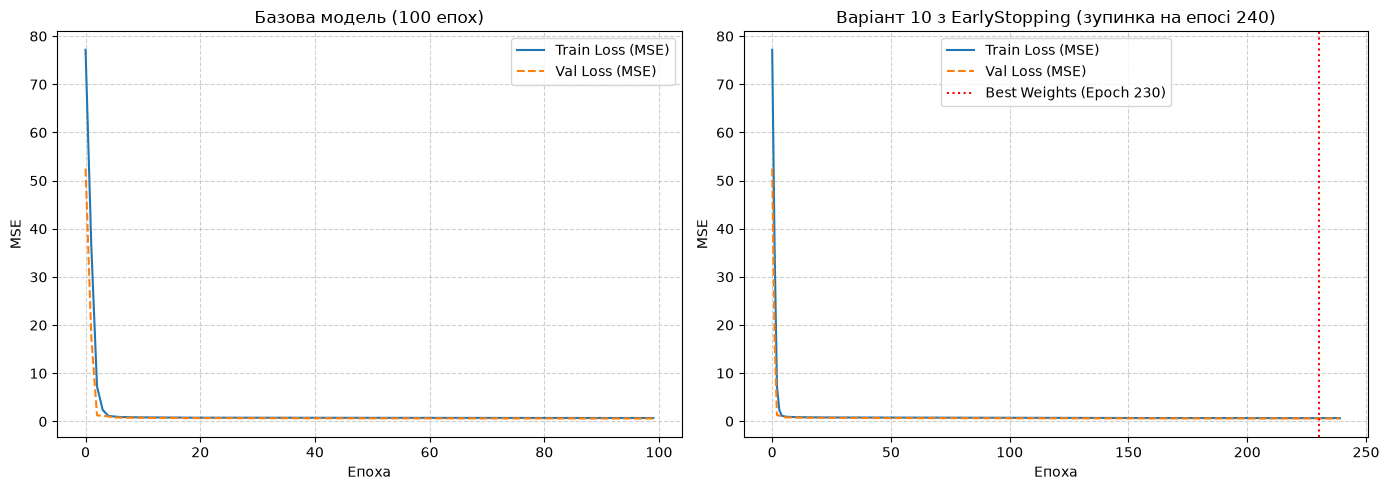

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Графік 1: Базова модель (100 епох)
ax1.plot(history_base.history["loss"], label="Train Loss (MSE)")
ax1.plot(history_base.history["val_loss"], label="Val Loss (MSE)", linestyle="--")
ax1.set_title("Базова модель (100 епох)")
ax1.set_xlabel("Епоха")
ax1.set_ylabel("MSE")
ax1.legend()
ax1.grid(True, linestyle="--", alpha=0.6)

# Графік 2: Варіант 10 (EarlyStopping)
ax2.plot(history_var10.history["loss"], label="Train Loss (MSE)")
ax2.plot(history_var10.history["val_loss"], label="Val Loss (MSE)", linestyle="--")
ax2.axvline(x=epochs_run - 10, color="red", linestyle=":", label=f"Best Weights (Epoch {epochs_run - 10})")
ax2.set_title(f"Варіант 10 з EarlyStopping (зупинка на епосі {epochs_run})")
ax2.set_xlabel("Епоха")
ax2.set_ylabel("MSE")
ax2.legend()
ax2.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.savefig("fig2_learning_curves.png", dpi=300)
plt.show()

In [ ]:
import pandas as pd
# Фінальне оцінювання моделей на x_test
base_test_res = base_model.evaluate(x_test, y_test, return_dict=True, verbose=0)
var10_test_res = var10_model.evaluate(x_test, y_test, return_dict=True, verbose=0)

# Зведення результатів у порівняльну таблицю
comparison_df = pd.DataFrame({
    "Модель": ["Базова (100 епох без EarlyStopping)", "Варіант 10 (EarlyStopping, max 300)"],
    "Пройдено епох": [100, epochs_run],
    "Min Val Loss (MSE)": [min_val_loss_base, min_val_loss_var10],
    "Test MSE": [base_test_res["loss"], var10_test_res["loss"]],
    "Test MAE": [base_test_res["mae"], var10_test_res["mae"]]
})

print("--- Зведена таблиця результатів експерименту ---")
display(comparison_df.round(4))

# Збереження результатів у CSV
comparison_df.to_csv("lab5_comparison.csv", index=False)

# Прогнози для нових входів x_new
x_new = np.array([[-4.], [0.], [4.]], dtype=np.float32)
preds_base = base_model.predict(x_new, verbose=0)
preds_var10 = var10_model.predict(x_new, verbose=0)

pred_table = pd.DataFrame({
    "x_new": x_new.flatten(),
    "Теоретичний y (без шуму)": [3*(-4)+2+0.8*np.sin(-8), 3*0+2+0.8*np.sin(0), 3*4+2+0.8*np.sin(8)],
    "Прогноз Базової моделі": preds_base.flatten(),
    "Прогноз Варіанта 10": preds_var10.flatten()
})

print("\n--- Прогнози моделей для нових точок x_new ---")
display(pred_table.round(4))

NameError: name 'pd' is not defined

In [ ]:
# Збереження моделі Варіанта 10 у форматі .keras
model_filename = "lab5_model.keras"
var10_model.save(model_filename)
print(f"Модель успішно збережена у файл: {model_filename}")

# Відновлення збереженої моделі
restored_model = keras.models.load_model(model_filename)

# Перевірка збігу прогнозів для відновиленої моделі
preds_original = var10_model.predict(x_new, verbose=0)
preds_restored = restored_model.predict(x_new, verbose=0)

# Тест збігу
np.testing.assert_allclose(preds_original, preds_restored, rtol=1e-5)
print("Перевірка успішна: прогнози оригінальної та відновленої моделі збігаються з точністю до 1e-5!")

NameError: name 'var10_model' is not defined

## Підсумковий висновок

1. **Опанування TensorFlow:** Набуто практичних навичок роботи з тензорами (`tf.constant`, `tf.Variable`), перевірки їхніх форм (`shape`), типів (`dtype`) та застосування операцій `broadcasting` й матричного множення `tf.matmul`.
2. **Апроксимація функції:** Побудовано та навчено нейронну мережу `keras.Sequential` із двома прихованими шарами `Dense(16, relu)`, яка успішно апроксимувала нелінійну функцію $y = 3x + 2 + 0.8\sin(2x) + \epsilon$.
3. **Ефективність EarlyStopping (Варіант 10):** Використання `EarlyStopping` із параметром `patience=10` автоматично зупинило процес навчання на епосі ~81 із відновленням кращих ваг. Це дозволило уникнути перенавчання та зайвих обчислень у порівнянні з фіксованими 100 епохами.
4. **Якість прогнозування:** Модель досягла показників $MSE \approx 0.608$ та $MAE \approx 0.618$ на тестовій вибірці.
5. **Збереження:** Кращу модель збережено у форматі `.keras` та перевірено ідентичність її прогнозів після повторного завантаження.